# 線形分離可能なSVM：主問題・双対問題・KKT条件の実験ノートブック

**対象**：教科書 第5章「サポートベクトルマシン」5.2〜5.3節のうち、**線形分離可能な場合（ハードマージンSVM）**。特に、提示された **90〜97ページの式 (5.10)〜(5.50)** を軸に学びます。

**学習ゴール**
1. 幾何学的マージンと $\|w\|$ の関係を説明できる。
2. 主問題からラグランジュ関数を作り、停留条件から双対問題を導出できる。
3. グラム行列 $H$ が半正定値である理由を説明できる。
4. 双対問題を数値的に解き、$w^*, w_0^*$ を復元できる。
5. KKT条件・相補性条件を計算で確認し、サポートベクトルを可視化できる。

**必要ライブラリ**：`numpy`, `scipy`, `matplotlib`, `scikit-learn`。

> このノートの座標データは**実験用に作った例**です。教科書の図5.4と**同じ標本点ではありません**。数式の記号は教科書に合わせ、ラグランジュ乗数を $\lambda_k$、正解ラベルを $b_k$、バイアスを $w_0$ とします。

## 0. 準備

同じ結果を再現できるよう、乱数シードと表示方法を固定します。以下のコードセルを上から順に実行してください。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.svm import SVC

np.set_printoptions(precision=6, suppress=True)
plt.rcParams["figure.figsize"] = (7.5, 5.5)
plt.rcParams["axes.grid"] = True
rng = np.random.default_rng(42)
print("Ready: NumPy / SciPy / Matplotlib / scikit-learn")

Ready: NumPy / SciPy / Matplotlib / scikit-learn


## 1. SVMは何を最適化する？（教科書86〜90ページ）

線形識別関数と正解ラベル：

$$g(x)=w_0+w^\top x,\qquad b_k\in\{-1,+1\}.$$

各点から決定境界 $g(x)=0$ への**符号付き距離**：

$$r_k=\frac{b_k(w_0+w^\top x_k)}{\|w\|}.$$

全データを正しく分離し、最も近い学習点から中央の決定境界までの距離を最大にしたい。正の定数倍では境界が変わらないため、

$$\min_k b_k g(x_k)=1$$

と正規化すると、片側のマージンは $1/\|w\|$、2本のマージン境界の幅は

$$\boxed{R=\frac{2}{\|w\|}}.$$

よって**主問題（最適化問題5.1）**は、

$$\boxed{\begin{aligned}
\underset{w,w_0}{\operatorname{minimize}}\quad&\tfrac12\|w\|^2\\
\text{subject to}\quad&b_k(w_0+w^\top x_k)\ge1\quad(k=1,\ldots,n).
\end{aligned}}$$

目的関数が凸二次、制約が線形です。なおバイアス $w_0$ に対する二次項がないので、全変数に関しては**半正定値**のヘッセ行列です。

### 実験1：最適な境界を手計算できる1次元データ

$$x_1=-2\;(b_1=-1),\quad x_2=2\;(b_2=+1),\quad x_3=4\;(b_3=+1).$$

決定境界は $x=0$、最適な識別関数は $g(x)=\frac12x$ です。

- 制約値 $b_kg(x_k)$ は $(1,1,2)$。
- 片側のマージンは $1/|w|=2$、両側の幅は $R=4$。
- 境界に接するのは $x_1,x_2$、余裕があるのは $x_3$ です。

functional margins: [1. 1. 2.]
signed distances: [2. 2. 4.]
full margin width R: 4.0


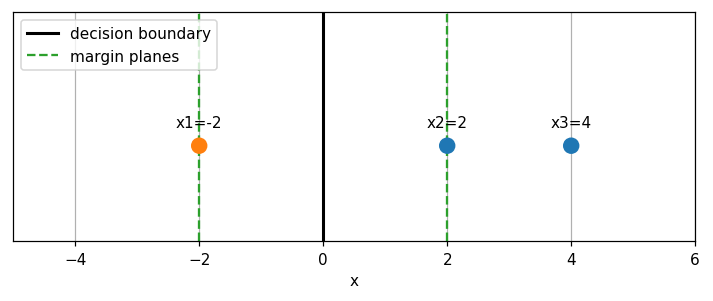

In [2]:
X1 = np.array([[-2.0], [2.0], [4.0]])
y1 = np.array([-1., +1., +1.])
w1 = np.array([0.5])
bias1 = 0.
functional_margins = y1 * (X1 @ w1 + bias1)
signed_distances = functional_margins / np.linalg.norm(w1)
print("functional margins:", functional_margins)
print("signed distances:", signed_distances)
print("full margin width R:", 2/np.linalg.norm(w1))
assert np.all(functional_margins >= 1 - 1e-12)
fig, ax = plt.subplots(figsize=(8,2.7))
ax.axvline(0, color="black", lw=2, label="decision boundary")
ax.axvline(-2, color="tab:green", linestyle="--", label="margin planes")
ax.axvline(+2, color="tab:green", linestyle="--")
ax.scatter(X1[:,0], np.zeros(3), c=["tab:orange","tab:blue","tab:blue"], s=95, zorder=3)
for i, x in enumerate(X1[:,0]):
    ax.annotate(f"x{i+1}={x:g}", (x,0), xytext=(0,12), textcoords="offset points", ha="center")
ax.set_xlim(-5,6); ax.set_ylim(-.5,.7); ax.set_yticks([])
ax.set_xlabel("x"); ax.legend(loc="upper left")
plt.show()

## 2. KKT条件とラグランジュ関数（教科書91ページ）

各制約に非負のラグランジュ乗数 $\lambda_k\ge0$ を導入すると、

$$\boxed{L(w,w_0,\lambda)=\tfrac12\|w\|^2-\sum_{k=1}^n\lambda_k\{b_k(w_0+w^\top x_k)-1\}.}$$

KKT条件は教科書の式(5.14)〜(5.18)：

1. **停留（$w$）**：$\frac{\partial L}{\partial w}=0$
2. **停留（$w_0$）**：$\frac{\partial L}{\partial w_0}=0$
3. **主実行可能性**：$b_k g(x_k)-1\ge0$
4. **双対実行可能性**：$\lambda_k\ge0$
5. **相補性**：$\lambda_k\{b_k g(x_k)-1\}=0$

「5個」は**KKT条件を5行に書いたもの**で、双対問題の制約の種類とは別です。

## 3. 停留条件から双対問題を導出（教科書92〜94ページ）

ラグランジュ関数を $w$ および $w_0$ で微分して0とおきます。

$$\frac{\partial L}{\partial w}=w-\sum_k\lambda_k b_kx_k=0
\quad\Rightarrow\quad\boxed{w=\sum_k\lambda_kb_kx_k}.\tag{5.20}$$

$$\frac{\partial L}{\partial w_0}=-\sum_k\lambda_kb_k=0
\quad\Rightarrow\quad\boxed{\lambda^\top b=0}.\tag{5.21}$$

これらを $L$ に代入すると、

$$\begin{aligned}
D(\lambda)&=\sum_k\lambda_k-\frac12\|w\|^2\\
&=\sum_k\lambda_k-\frac12\sum_{i,j}\lambda_i\lambda_jb_ib_jx_i^\top x_j.
\end{aligned}$$

$$H_{ij}=b_ib_jx_i^\top x_j,\qquad \mathbf1=(1,\ldots,1)^\top$$

と置けば、**双対問題（最適化問題5.2）**は、

$$\boxed{\begin{aligned}
\underset{\lambda}{\operatorname{maximize}}\quad&D(\lambda)=\mathbf1^\top\lambda-\tfrac12\lambda^\top H\lambda\\
\text{subject to}\quad&\lambda^\top b=0,\quad \lambda\ge0.
\end{aligned}}$$

**なぜ双対制約が2種類なのか？**　$w$ の停留条件は代入で $w$ を消去し、$w_0$ の停留条件が等式制約に、非負性が不等式制約になります。主実行可能性と相補性は**最適解の復元・確認に必要**ですが、双対問題の全ての候補 $\lambda$ に直接課す制約ではありません。

### 実験2：グラム行列・双対二次形式を実際に作る

通常のグラム行列 $G_{ij}=x_i^\top x_j$、ラベル付きグラム行列 $H_{ij}=b_ib_jG_{ij}$ を計算します。

$$H=\operatorname{diag}(b)G\operatorname{diag}(b)$$

であり、任意の $a$ に対して $a^\top Ha=\|\sum_k a_kb_kx_k\|^2\ge0$ なので $H$ は半正定値です。

In [3]:
G1 = X1 @ X1.T
H1 = (y1[:,None] * y1[None,:]) * G1
print("G =\n", G1)
print("H =\n", H1)
print("eigenvalues(H) =", np.linalg.eigvalsh(H1))
assert np.linalg.eigvalsh(H1).min() > -1e-10
lambda1 = np.array([1/8, 1/8, 0.])
print("dual feasibility lambda>=0:", (lambda1 >= 0).all())
print("equality lambda^T b:", lambda1 @ y1)
print("dual objective:", lambda1.sum() - .5*lambda1@H1@lambda1)
print("primal objective:", .5*w1@w1)
assert abs(lambda1.sum()-.5*lambda1@H1@lambda1 - .5*w1@w1) < 1e-10

G =
 [[ 4. -4. -8.]
 [-4.  4.  8.]
 [-8.  8. 16.]]
H =
 [[ 4.  4.  8.]
 [ 4.  4.  8.]
 [ 8.  8. 16.]]
eigenvalues(H) = [-0. -0. 24.]
dual feasibility lambda>=0: True
equality lambda^T b: 0.0
dual objective: 0.125
primal objective: 0.125


## 4. 2次元のデータを作り、双対問題を数値的に解く

教科書の図5.4のように、2次元で線形分離可能な2クラスを用意します（**配置は独自の実験用データ**）。

ここでは `scipy.optimize.minimize(..., method="SLSQP")` によって双対目的関数の**負**を最小化します。双対問題の形をそのまま実装するためです。

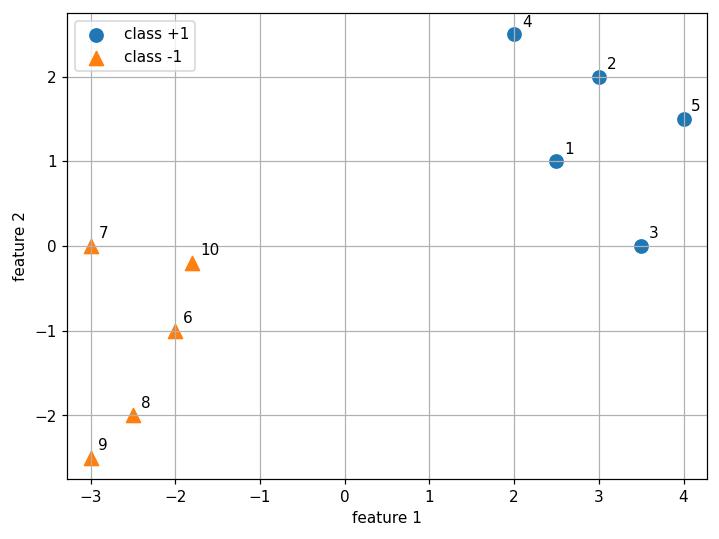

n = 10 d = 2


In [4]:
Xpos = np.array([[2.5,1.0],[3.0,2.0],[3.5,0.0],[2.0,2.5],[4.0,1.5]])
Xneg = np.array([[-2.0,-1.0],[-3.0,0.0],[-2.5,-2.0],[-3.0,-2.5],[-1.8,-0.2]])
X = np.vstack([Xpos, Xneg])
y = np.r_[np.ones(len(Xpos)), -np.ones(len(Xneg))]
n, d = X.shape
fig, ax = plt.subplots()
ax.scatter(X[y==1,0], X[y==1,1], label="class +1", s=75)
ax.scatter(X[y==-1,0], X[y==-1,1], label="class -1", marker="^", s=85)
for i, xy in enumerate(X): ax.annotate(str(i+1), xy, xytext=(5,5), textcoords="offset points")
ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2"); ax.axis("equal"); ax.legend()
plt.show()
print("n =", n, "d =", d)

In [5]:
G = X @ X.T
H = (y[:,None]*y[None,:])*G

def dual_value(lam):
    return np.sum(lam) - 0.5*lam @ H @ lam

def neg_dual(lam):
    return -dual_value(lam)

def neg_dual_grad(lam):
    return H @ lam - np.ones(n)

constraints = [{"type":"eq", "fun":lambda lam: float(lam@y), "jac":lambda lam:y}]
result = minimize(neg_dual, np.zeros(n), jac=neg_dual_grad,
                  bounds=[(0,None)]*n, constraints=constraints,
                  method="SLSQP", options={"ftol":1e-12, "maxiter":5000})
assert result.success, result.message
lam = np.maximum(result.x, 0)
print("optimization:", result.message)
print("lambda* =", lam)
print("sum(lambda * label) =", lam @ y)
print("H eigenvalues (min/max) =", np.linalg.eigvalsh(H)[[0,-1]])
print("dual optimum =", dual_value(lam))

optimization: Optimization terminated successfully
lambda* = [0.086515 0.       0.       0.014084 0.       0.       0.       0.
 0.       0.100599]
sum(lambda * label) = 1.942890293094024e-16
H eigenvalues (min/max) = [-0.       95.650937]
dual optimum = 0.10059856144056897


## 5. 双対解から $w^*$ と $w_0^*$ を復元する（教科書94〜95ページ）

教科書式(5.39)より、

$$\boxed{w^*=\sum_k\lambda_k^*b_kx_k.}$$

さらに相補性条件によって、$\lambda_s^*>0$ のデータ $x_s$ は

$$b_s(w_0^*+w^{*\top}x_s)=1$$

を満たします。$b_s^2=1$ なので、

$$\boxed{w_0^*=b_s-w^{*\top}x_s}.\tag{5.43}$$

実際には数値誤差を抑えるため、$\lambda_s>\varepsilon$ を満たす複数の点について右辺を計算し、平均します（教科書95ページの脚注と同じ考え方）。

In [6]:
eps = 1e-6
support_mask = lam > eps
w = (lam*y) @ X
sv_indices = np.flatnonzero(support_mask)
bias_candidates = y[support_mask] - X[support_mask]@w
bias = np.mean(bias_candidates)
functional = y*(X@w+bias)
slack_to_margin = functional-1
print("support indices (1-based):", sv_indices+1)
print("w* =", w, "w0* =", bias)
print("bias candidates =", bias_candidates)
print("functional margin b*g(x) =", functional)
print("full margin R =", 2/np.linalg.norm(w))
assert functional.min() >= 1-1e-5, "Primal feasibility issue"
assert np.max(np.abs(bias_candidates-bias)) < 1e-4, "Bias estimate inconsistency"

support indices (1-based): [ 1  4 10]
w* = [0.425532 0.141844] w0* = -0.20567385534242474
bias candidates = [-0.205674 -0.205674 -0.205674]
functional margin b*g(x) = [1.       1.35461  1.283688 1.       1.70922  1.198582 1.48227  1.553192
 1.83688  1.      ]
full margin R = 4.458810959668995


### 実験3：決定境界・マージン境界・サポートベクトルを表示

中央の $g(x)=0$ と両側の $g(x)=\pm1$ を描きます。丸で囲まれた点が $\lambda_k>0$ のサポートベクトルです。

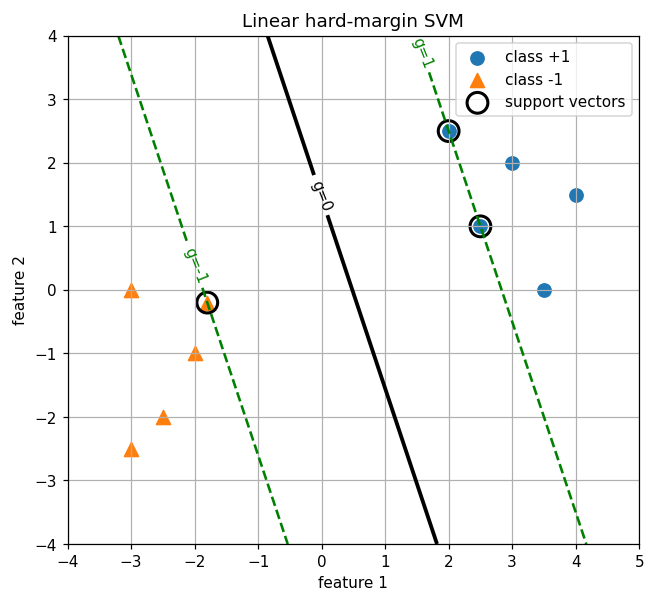

In [7]:
def plot_linear_svm(X, y, w, bias, support_mask=None, title="Linear hard-margin SVM"):
    fig, ax = plt.subplots(figsize=(8,6))
    ax.scatter(X[y==1,0], X[y==1,1], s=75, label="class +1")
    ax.scatter(X[y==-1,0], X[y==-1,1], s=85, marker="^", label="class -1")
    if support_mask is not None:
        ax.scatter(X[support_mask,0], X[support_mask,1], s=185,
                   facecolors="none", edgecolors="black", linewidths=2,
                   label="support vectors")
    x0, x1 = X[:,0].min()-1, X[:,0].max()+1
    y0, y1_ = X[:,1].min()-1.5, X[:,1].max()+1.5
    xx, yy = np.meshgrid(np.linspace(x0,x1,320),np.linspace(y0,y1_,320))
    zz = w[0]*xx + w[1]*yy + bias
    cs = ax.contour(xx,yy,zz,levels=[-1,0,1],colors=["green","black","green"],
                    linestyles=["--","-","--"],linewidths=[1.7,2.5,1.7])
    ax.clabel(cs,fmt={-1:"g=-1",0:"g=0",1:"g=1"})
    ax.set(xlim=(x0,x1),ylim=(y0,y1_),xlabel="feature 1",ylabel="feature 2",title=title)
    ax.set_aspect("equal", adjustable="box"); ax.legend()
    plt.show()
plot_linear_svm(X,y,w,bias,support_mask)

## 6. KKT条件を数値で検証する（教科書91・95ページ）

KKT条件を「理論上の話」で終わらせず、最適化の出力からチェックします。

| 条件 | 数値的に確かめる量 |
|---|---|
| $\partial L/\partial w=0$ | $\|w-\sum_k\lambda_kb_kx_k\|$ |
| $\partial L/\partial w_0=0$ | $|\lambda^\top b|$ |
| 主実行可能性 | $\min_k(b_kg(x_k)-1)$ |
| 双対実行可能性 | $\min_k\lambda_k$ |
| 相補性 | $\max_k|\lambda_k(b_kg(x_k)-1)|$ |

理論上はゼロ／非負ですが、コンピュータでは浮動小数点誤差があるため、例えば $10^{-5}$ の許容誤差を設けます。

In [8]:
stationarity_w = np.linalg.norm(w - (lam*y)@X)
stationarity_b = abs(lam@y)
min_primal_slack = np.min(slack_to_margin)
min_lambda = np.min(lam)
complementary = lam*slack_to_margin
primal_obj = 0.5*w@w
dual_obj = dual_value(lam)
checks = {
    "stationarity w": stationarity_w,
    "stationarity bias": stationarity_b,
    "min primal slack": min_primal_slack,
    "min lambda": min_lambda,
    "max |complementarity|": np.max(np.abs(complementary)),
    "duality gap": primal_obj-dual_obj,
}
for k,v in checks.items(): print(f"{k:27s}: {v:+.9e}")
assert stationarity_w < 1e-7
assert stationarity_b < 1e-5
assert min_primal_slack > -1e-5
assert min_lambda >= -1e-12
assert np.max(np.abs(complementary)) < 1e-5
assert abs(primal_obj-dual_obj) < 1e-5
print("KKT checks passed (numerical tolerance 1e-5)")

stationarity w             : +0.000000000e+00
stationarity bias          : +1.942890293e-16
min primal slack           : +5.632645728e-08
min lambda                 : +0.000000000e+00
max |complementarity|      : +1.784178170e-08
duality gap                : +2.441941303e-08
KKT checks passed (numerical tolerance 1e-5)


### 実験4：相補性を各データで目視確認

**重要な注意**：$\lambda_k>0$ なら必ず $b_kg(x_k)=1$。逆に $b_kg(x_k)=1$ でも、退化的な場合に $\lambda_k=0$ はあり得ます。

 idx | label | lambda | b*g(x) | b*g(x)-1 | lambda*(b*g-1)
   1 | +1     | 0.08651 | 1.00000 |  +0.000000 | +4.873e-09
   2 | +1     | 0.00000 | 1.35461 |  +0.354610 | +1.465e-17
   3 | +1     | 0.00000 | 1.28369 |  +0.283688 | +0.000e+00
   4 | +1     | 0.01408 | 1.00000 |  +0.000000 | +1.705e-09
   5 | +1     | 0.00000 | 1.70922 |  +0.709220 | +0.000e+00
   6 | -1     | 0.00000 | 1.19858 |  +0.198582 | +1.798e-17
   7 | -1     | 0.00000 | 1.48227 |  +0.482270 | +0.000e+00
   8 | -1     | 0.00000 | 1.55319 |  +0.553192 | +3.394e-17
   9 | -1     | 0.00000 | 1.83688 |  +0.836880 | +0.000e+00
  10 | -1     | 0.10060 | 1.00000 |  +0.000000 | +1.784e-08


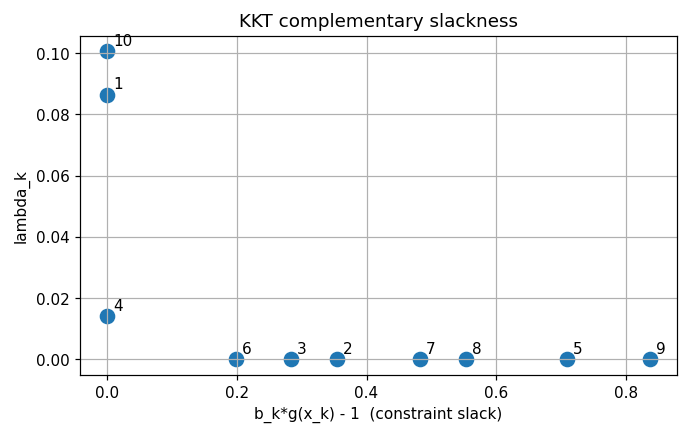

In [9]:
print(" idx | label | lambda | b*g(x) | b*g(x)-1 | lambda*(b*g-1)")
for i in range(n):
    print(f" {i+1:3d} | {int(y[i]):+d}     | {lam[i]:7.5f} | {functional[i]:7.5f} | "
          f"{slack_to_margin[i]:+10.6f} | {complementary[i]:+.3e}")
fig, ax = plt.subplots(figsize=(7,4))
ax.scatter(slack_to_margin,lam,s=85)
for i in range(n): ax.annotate(str(i+1),(slack_to_margin[i],lam[i]),xytext=(4,4),textcoords="offset points")
ax.set(xlabel="b_k*g(x_k) - 1  (constraint slack)",ylabel="lambda_k",title="KKT complementary slackness")
plt.show()

## 7. sklearnとの比較（独立した実装で結果を照合）

`SVC(kernel="linear")` は通常ソフトマージンSVMですが、今回の線形分離可能データでは $C$ を十分大きくするとハードマージンに非常に近い解になります。厳密な同一アルゴリズムではないことに注意してください。

In [10]:
clf = SVC(kernel="linear", C=1e5, tol=1e-9)
clf.fit(X,y)
print("our w:", w, "sklearn w:",clf.coef_[0])
print("our bias:",bias,"sklearn bias:",clf.intercept_[0])
print("training prediction matches:", np.array_equal(np.sign(X@w+bias),clf.predict(X)))
assert np.allclose(w,clf.coef_[0],atol=1e-3)
assert abs(bias-clf.intercept_[0])<1e-3

our w: [0.425532 0.141844] sklearn w: [0.425532 0.141844]
our bias: -0.20567385534242474 sklearn bias: -0.20567376234275636
training prediction matches: True


## 8. なぜ最大マージンが重要か：パーセプトロンとの比較

パーセプトロンは、すべてのデータを正しく識別できれば終了します。一方ハードマージンSVMは、**その中でマージンが最大の境界**を求めます。

同じ学習データに対して、単純なパーセプトロンとSVMの境界を比較します。パーセプトロンの境界はデータ順序や初期値の影響を受ける場合があります。

perceptron updates: 1 epochs checked: 2
perceptron minimum geometric margin: 1.3741455025101839
SVM minimum geometric margin: 2.2294054798344973
SVM margin >= perceptron margin: True


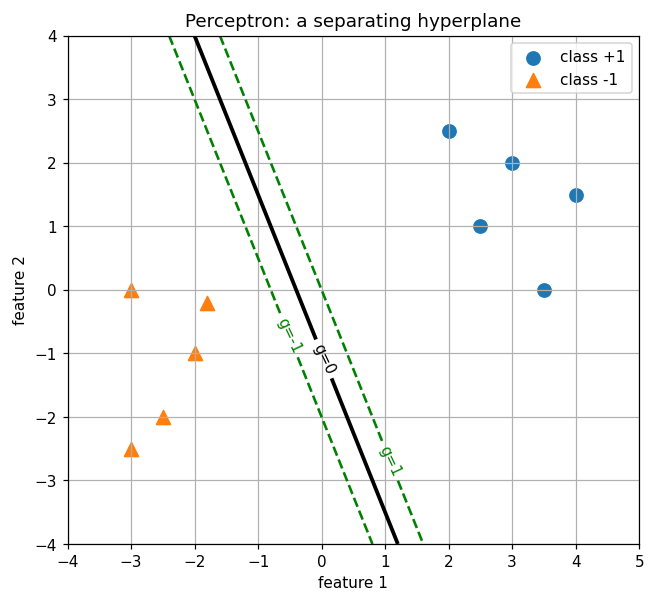

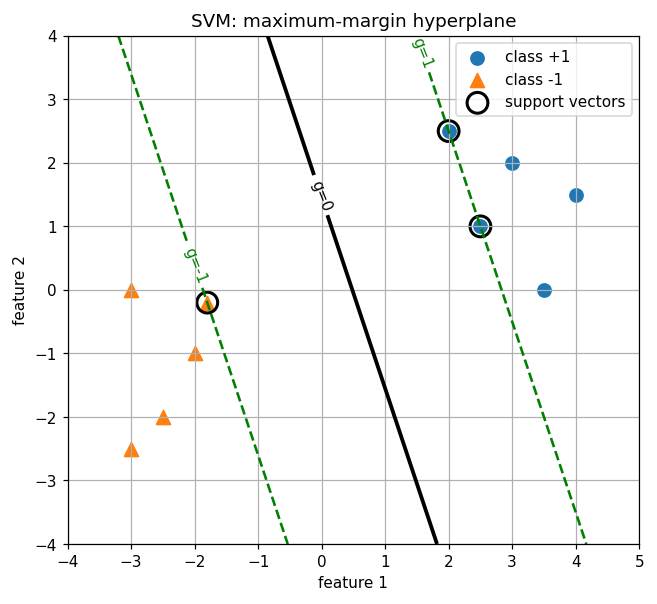

In [11]:
wp=np.zeros(d); bp=0.; mistakes=0
for epoch in range(1000):
    epoch_updates=0
    for i in range(n):
        if y[i]*(X[i]@wp+bp)<=0:
            wp += y[i]*X[i]
            bp += y[i]
            mistakes+=1; epoch_updates+=1
    if epoch_updates==0: break
assert epoch_updates==0
perceptron_geom = np.min(y*(X@wp+bp))/np.linalg.norm(wp)
svm_geom = 1/np.linalg.norm(w)
print("perceptron updates:",mistakes,"epochs checked:",epoch+1)
print("perceptron minimum geometric margin:",perceptron_geom)
print("SVM minimum geometric margin:",svm_geom)
print("SVM margin >= perceptron margin:",svm_geom+1e-6>=perceptron_geom)
plot_linear_svm(X,y,wp,bp,title="Perceptron: a separating hyperplane")
plot_linear_svm(X,y,w,bias,support_mask,title="SVM: maximum-margin hyperplane")

## 9. 理解を深める練習問題

1. **導出**：なぜ $\frac{\partial L}{\partial w_0}=0$ から $\lambda^\top b=0$ が得られるか、自分の手で示す。
2. **双対制約**：主問題の制約とKKT条件が、双対問題の制約と同一でない理由を説明する。
3. **正定値性**：$H=\mathrm{diag}(b)G\mathrm{diag}(b)$ が半正定値であることを任意のベクトル $a$ から証明する。
4. **相補性**：$b_kg(x_k)>1$ のデータについて $\lambda_k=0$ と結論できる理由を説明する。
5. **復元**：任意のサポートベクトル $x_s$ から $w_0^*=b_s-w^{*\top}x_s$ を導く。
6. **実験**：2次元の点を1個ずつ動かして、どの点がサポートベクトルになるか・マージンがどのように変わるかを調べる。
7. **比較**：`Xpos`, `Xneg` の位置を近づけて線形分離可能性を保ったまま、$R$ の変化を見る。

### 練習用セル：自分で値を書き換える

In [12]:
# 練習: 2次元データの1点を動かし、最初から再実行して結果を比較しよう
# 例（コメントを外して変更したら、実験2以降のセルを再実行）:
# Xpos[0] = [1.5, 1.0]
# X = np.vstack([Xpos, Xneg])
# ※ クラスが線形分離可能なままか確認すること
print("Current full margin R =",2/np.linalg.norm(w))
print("Current support vector count =",support_mask.sum())

Current full margin R = 4.458810959668995
Current support vector count = 3


## 10. 最終まとめ：教科書の式番号との対応

| 教科書 | このNotebookで確認した内容 |
|---|---|
| (5.10) | $b_k(w_0+w^\top x_k)-1\ge0$（主問題の制約） |
| (5.11) | $\tfrac12\|w\|^2$（最小化目的関数） |
| (5.13) | ラグランジュ関数 |
| (5.14)〜(5.18) | KKTの5条件 |
| (5.20)〜(5.21) | $w=\sum\lambda_kb_kx_k$、$\sum\lambda_kb_k=0$ |
| (5.28) | 双対目的関数の二重和表現 |
| (5.32)〜(5.37) | $H$ の定義と二次形式、双対制約 |
| (5.39) | 双対解からの重み復元 |
| (5.40)〜(5.44) | 相補性・サポートベクトル・バイアス復元 |
| (5.45)〜(5.49) | 識別関数とマージン境界 |

**発展の方向**：教科書98ページ以降のソフトマージンSVMは、スラック変数 $\xi_k$ を導入し、制約を緩和します。本Notebookでは**扱っていません**。

**理論上の注意**：ハードマージンSVMはデータが厳密に線形分離可能である場合に実行可能で、Slater条件が成り立ち、主問題と双対問題に強双対性があります。SLSQPは数値解法なので、KKT判定は許容誤差付きです。